# **Credit Risk Scoring: German Credit**

### **Imports and Setup**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'Liberation Serif', 'FreeSerif', 'DejaVu Serif'],
    'axes.grid': True, 'grid.alpha': 0.3, 'axes.axisbelow': True,
    'axes.spines.top': False, 'axes.spines.right': False,
})
SKY, SKY_EDGE = '#9AD0EC', '#5BA8D6'
YELLOW, YELLOW_EDGE = '#F8DC75', '#D9B93A'
GRAY = '#8A94A6'

import warnings
import shap
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import chi2_contingency, ks_2samp
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, brier_score_loss, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score)
from sklearn.model_selection import (GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold,
                                     cross_val_predict, cross_val_score, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.calibration import calibration_curve

warnings.filterwarnings('ignore')
SEED = 42
DIVERGING = LinearSegmentedColormap.from_list('div', [SKY_EDGE, '#FFFFFF', YELLOW_EDGE])
SEQ = LinearSegmentedColormap.from_list('seq', ['#FFFFFF', SKY])

## **1 · Data cleaning and EDA**

### **1.1 · Load, name the columns, set the target**

In [2]:
COLUMNS = ['checking', 'duration', 'history', 'purpose', 'amount', 'savings', 'employment',
           'installment_rate', 'personal_status', 'debtors', 'residence', 'property', 'age',
           'other_plans', 'housing', 'existing_credits', 'job', 'dependents', 'telephone', 'foreign', 'class']
raw = pd.read_csv('german.data', sep=' ', header=None, names=COLUMNS)

# german.doc codes: 1 = good, 2 = bad. The brief wants 0 = good, 1 = bad.
raw['default'] = (raw['class'] == 2).astype(int)
raw = raw.drop(columns='class')

LABELS = {
    'checking': {'A11': 'below 0 DM', 'A12': '0-200 DM', 'A13': '200 DM or more', 'A14': 'no account'},
    'history': {'A30': 'no credits / all paid', 'A31': 'all paid at this bank', 'A32': 'paid duly so far',
                'A33': 'delay in the past', 'A34': 'critical / other credits'},
    'purpose': {'A40': 'car (new)', 'A41': 'car (used)', 'A42': 'furniture', 'A43': 'radio/TV', 'A44': 'appliances',
                'A45': 'repairs', 'A46': 'education', 'A47': 'vacation', 'A48': 'retraining', 'A49': 'business',
                'A410': 'other'},
    'savings': {'A61': 'below 100 DM', 'A62': '100-500 DM', 'A63': '500-1000 DM', 'A64': '1000 DM or more', 'A65': 'unknown / none'},
    'employment': {'A71': 'unemployed', 'A72': 'under 1 year', 'A73': '1-4 years', 'A74': '4-7 years', 'A75': '7 years or more'},
    'personal_status': {'A91': 'male divorced', 'A92': 'female div./married', 'A93': 'male single',
                        'A94': 'male married', 'A95': 'female single'},
    'debtors': {'A101': 'none', 'A102': 'co-applicant', 'A103': 'guarantor'},
    'property': {'A121': 'real estate', 'A122': 'savings/insurance', 'A123': 'car/other', 'A124': 'none / unknown'},
    'other_plans': {'A141': 'bank', 'A142': 'stores', 'A143': 'none'},
    'housing': {'A151': 'rent', 'A152': 'own', 'A153': 'free'},
    'job': {'A171': 'unskilled non-resident', 'A172': 'unskilled resident', 'A173': 'skilled', 'A174': 'management / highly qualified'},
    'telephone': {'A191': 'no', 'A192': 'yes'},
    'foreign': {'A201': 'yes', 'A202': 'no'},
}
credit = raw.copy()
for col, mapping in LABELS.items():
    credit[col] = credit[col].map(mapping)

CATEGORICAL = list(LABELS)
NUMERIC = ['duration', 'amount', 'installment_rate', 'residence', 'age', 'existing_credits', 'dependents']
print('Rows:', len(credit), '| numeric:', len(NUMERIC), '| categorical:', len(CATEGORICAL))
credit.head()

Rows: 1000 | numeric: 7 | categorical: 13


,checking,duration,history,purpose,amount,savings,employment,installment_rate,personal_status,debtors,residence,property,age,other_plans,housing,existing_credits,job,dependents,telephone,foreign,default
0,below 0 DM,6,critical / other credits,radio/TV,1169,unknown / none,7 years or more,4,male single,none,4,real estate,67,none,own,2,skilled,1,yes,yes,0
1,0-200 DM,48,paid duly so far,radio/TV,5951,below 100 DM,1-4 years,2,female div./married,none,2,real estate,22,none,own,1,skilled,1,no,yes,1
2,no account,12,critical / other credits,education,2096,below 100 DM,4-7 years,2,male single,none,3,real estate,49,none,own,1,unskilled resident,2,no,yes,0
3,below 0 DM,42,paid duly so far,furniture,7882,below 100 DM,4-7 years,2,male single,guarantor,4,savings/insurance,45,none,free,1,skilled,2,no,yes,0
4,below 0 DM,24,delay in the past,car (new),4870,below 100 DM,1-4 years,3,male single,none,4,none / unknown,53,none,free,2,skilled,2,no,yes,1


### **1.2 · Split first, then explore the training rows only**

In [3]:
train, test = train_test_split(credit, test_size=0.3, stratify=credit['default'], random_state=SEED)
train, test = train.reset_index(drop=True), test.reset_index(drop=True)
print('Train:', train.shape, '| test:', test.shape)
print('Default rate train / test:', round(train['default'].mean(), 3), '/', round(test['default'].mean(), 3))

Train: (700, 21) | test: (300, 21)
Default rate train / test: 0.3 / 0.3


### **1.3 · Data quality and class balance**

In [4]:
quality = pd.DataFrame({
    'type': ['numeric' if c in NUMERIC else 'categorical' for c in credit.drop(columns='default').columns],
    'missing': credit.drop(columns='default').isna().sum().values,
    'unique': credit.drop(columns='default').nunique().values,
}, index=credit.drop(columns='default').columns)
display(quality.T)
n_bad, n_good = int(credit['default'].sum()), int((1 - credit['default']).sum())
print('Missing values in total:', int(credit.isna().sum().sum()))
print('Duplicate rows:', int(credit.duplicated().sum()))
print(f'Good: {n_good} | bad: {n_bad} | default rate {n_bad / len(credit):.0%} | imbalance ratio {n_good / n_bad:.2f} : 1')

,checking,duration,history,purpose,amount,savings,employment,installment_rate,personal_status,debtors,residence,property,age,other_plans,housing,existing_credits,job,dependents,telephone,foreign
type,categorical,numeric,categorical,categorical,numeric,categorical,categorical,numeric,categorical,categorical,numeric,categorical,numeric,categorical,categorical,numeric,categorical,numeric,categorical,categorical
missing,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
unique,4,33,5,10,921,5,5,4,4,3,4,4,53,3,3,4,4,2,2,2


Missing values in total: 0
Duplicate rows: 0
Good: 700 | bad: 300 | default rate 30% | imbalance ratio 2.33 : 1


### **1.4 · Distributions and outliers: credit amount and duration**

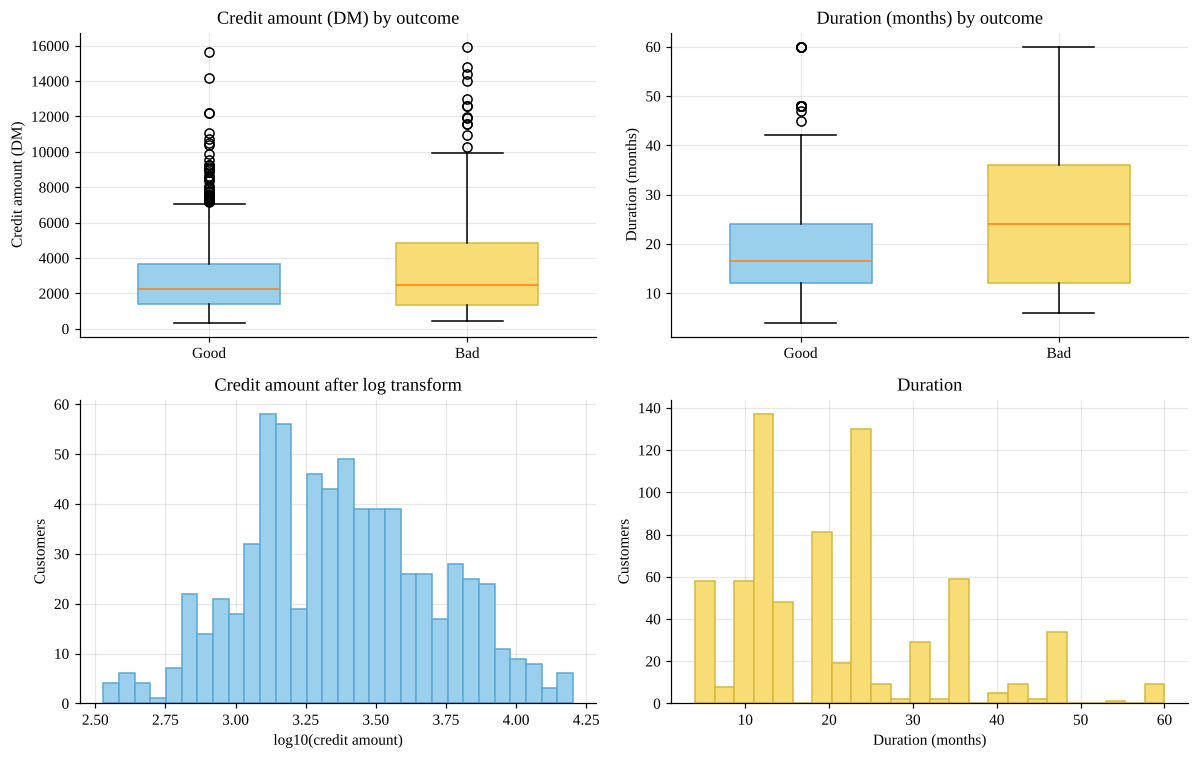

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
groups = [train.loc[train['default'] == 0], train.loc[train['default'] == 1]]
for ax, col, title in zip(axes[0], ['amount', 'duration'], ['Credit amount (DM)', 'Duration (months)']):
    bp = ax.boxplot([g[col] for g in groups], tick_labels=['Good', 'Bad'], patch_artist=True, widths=0.55)
    for patch, c, e in zip(bp['boxes'], [SKY, YELLOW], [SKY_EDGE, YELLOW_EDGE]):
        patch.set_facecolor(c)
        patch.set_edgecolor(e)
    ax.set_title(f'{title} by outcome')
    ax.set_ylabel(title)
axes[1][0].hist(np.log10(train['amount']), bins=30, color=SKY, edgecolor=SKY_EDGE)
axes[1][0].set_xlabel('log10(credit amount)')
axes[1][0].set_title('Credit amount after log transform')
axes[1][1].hist(train['duration'], bins=24, color=YELLOW, edgecolor=YELLOW_EDGE)
axes[1][1].set_xlabel('Duration (months)')
axes[1][1].set_title('Duration')
for ax in axes[1]:
    ax.set_ylabel('Customers')
plt.tight_layout()
plt.show()

In [6]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return int(((s < q1 - 1.5 * (q3 - q1)) | (s > q3 + 1.5 * (q3 - q1))).sum())


out = pd.DataFrame({'IQR outliers': [iqr_outliers(train[c]) for c in ['amount', 'duration']],
                    'median': [train[c].median() for c in ['amount', 'duration']],
                    'max': [train[c].max() for c in ['amount', 'duration']],
                    'bad rate, top 5%': [train.loc[train[c] >= train[c].quantile(0.95), 'default'].mean() for c in ['amount', 'duration']]},
                   index=['amount', 'duration']).round(3)
out

,IQR outliers,median,max,"bad rate, top 5%"
amount,46,2319.5,15945,0.514
duration,46,18.0,60,0.535


### **1.5 · Correlation and association with default**

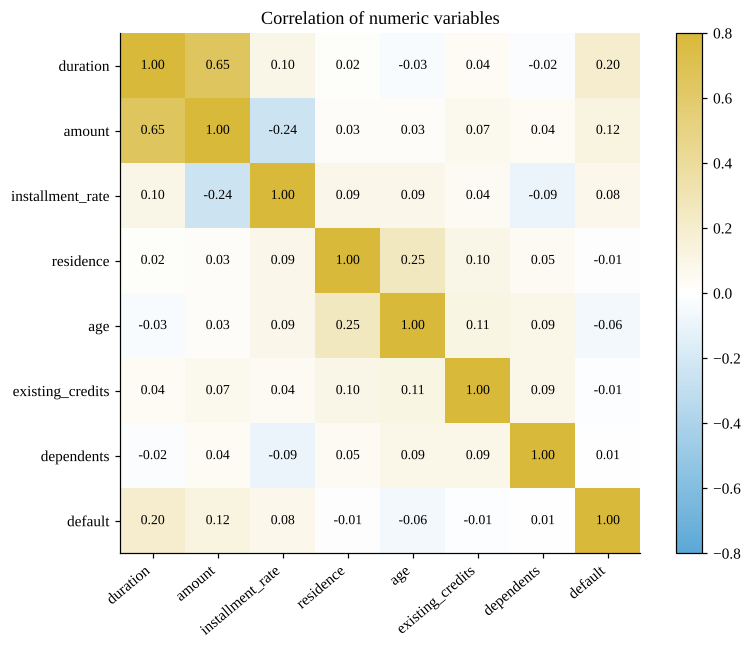

In [7]:
corr = train[NUMERIC + ['default']].corr()
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(corr, cmap=DIVERGING, vmin=-0.8, vmax=0.8)
ax.set_xticks(range(len(corr)), corr.columns, rotation=40, ha='right')
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=9)
ax.grid(False)
ax.set_title('Correlation of numeric variables')
fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

In [8]:
def woe_iv(frame, col, target='default', bins=5):
    s = frame[col]
    if col in NUMERIC and s.nunique() > 8:
        s = pd.qcut(s, bins, duplicates='drop')
    g = frame.groupby(s, observed=True)[target].agg(['sum', 'count'])
    bad, good = g['sum'] + 0.5, g['count'] - g['sum'] + 0.5
    pb, pg = bad / bad.sum(), good / good.sum()
    woe = np.log(pg / pb)
    return ((pg - pb) * woe).sum()


def cramers_v(frame, col, target='default'):
    table = pd.crosstab(frame[col], frame[target])
    chi2 = chi2_contingency(table)[0]
    return np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))


assoc = pd.DataFrame({'IV': {c: woe_iv(train, c) for c in NUMERIC + CATEGORICAL},
                      "Cramer's V": {c: cramers_v(train, c) if c in CATEGORICAL else np.nan for c in NUMERIC + CATEGORICAL}})
assoc = assoc.sort_values('IV', ascending=False)
assoc.round(3).T

,checking,history,savings,duration,property,employment,purpose,other_plans,housing,foreign,amount,age,personal_status,installment_rate,debtors,job,existing_credits,telephone,residence,dependents
IV,0.630,0.252,0.221,0.184,0.139,0.139,0.129,0.118,0.103,0.066,0.064,0.047,0.039,0.033,0.026,0.024,0.004,0.003,0.002,0.0
Cramer's V,0.342,0.231,0.206,NaN,0.174,0.174,0.167,0.163,0.150,0.094,NaN,NaN,0.092,NaN,0.075,0.072,NaN,0.022,NaN,NaN


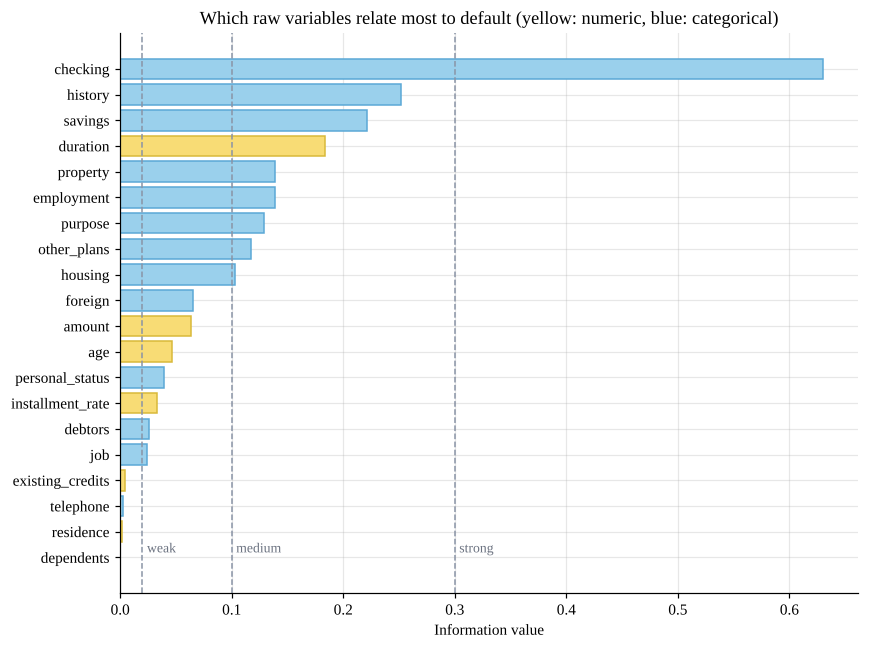

In [9]:
iv = assoc['IV'].sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
colors = [YELLOW if c in NUMERIC else SKY for c in iv.index]
edges = [YELLOW_EDGE if c in NUMERIC else SKY_EDGE for c in iv.index]
ax.barh(iv.index, iv.values, color=colors, edgecolor=edges)
for x, label in [(0.02, 'weak'), (0.1, 'medium'), (0.3, 'strong')]:
    ax.axvline(x, color=GRAY, linestyle='--', linewidth=1)
    ax.text(x + 0.004, 0.2, label, color='#6B7280', fontsize=9)
ax.set_xlabel('Information value')
ax.set_title('Which raw variables relate most to default (yellow: numeric, blue: categorical)')
plt.tight_layout()
plt.show()

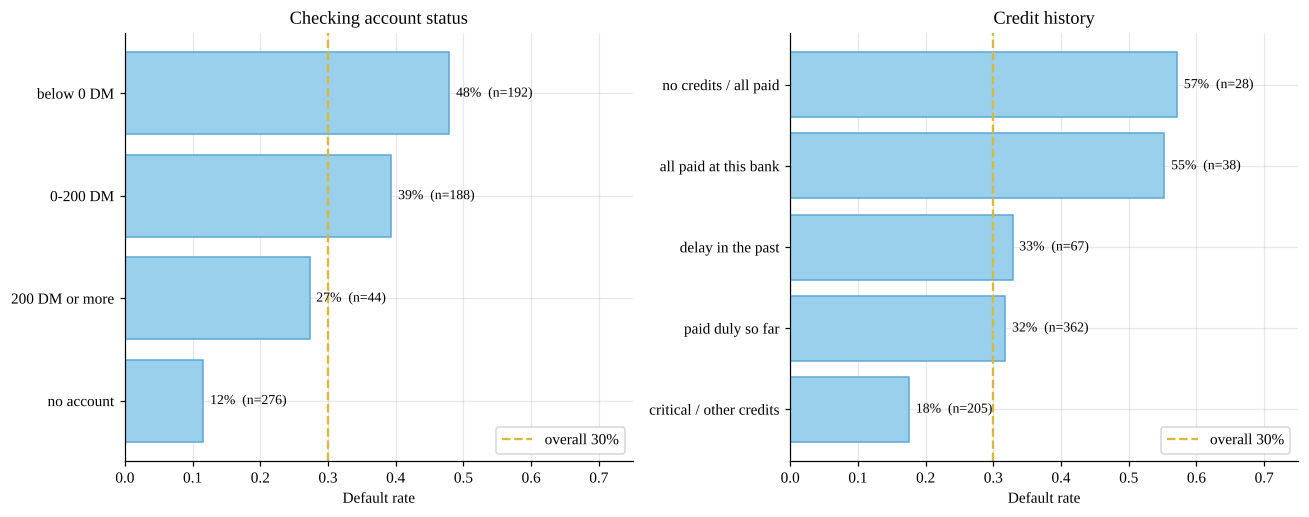

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
overall = train['default'].mean()
for ax, col, title in zip(axes, ['checking', 'history'], ['Checking account status', 'Credit history']):
    g = train.groupby(col)['default'].agg(['mean', 'count']).sort_values('mean')
    bars = ax.barh(g.index, g['mean'], color=SKY, edgecolor=SKY_EDGE)
    ax.axvline(overall, color=YELLOW_EDGE, linestyle='--', linewidth=1.5, label=f'overall {overall:.0%}')
    for b, (rate, n) in zip(bars, zip(g['mean'], g['count'])):
        ax.text(rate + 0.01, b.get_y() + b.get_height() / 2, f'{rate:.0%}  (n={n})', va='center', fontsize=9)
    ax.set_xlim(0, 0.75)
    ax.set_xlabel('Default rate')
    ax.set_title(title)
    ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

## **2 · Feature engineering and preprocessing**

### **2.1 · Missing values, encoding and scaling**

In [11]:
print('Missing values:', int(credit.isna().sum().sum()))


def make_pipeline(model, numeric, categorical, scale=False):
    num_step = StandardScaler() if scale else 'passthrough'
    pre = ColumnTransformer([('num', num_step, numeric),
                             ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical)],
                            verbose_feature_names_out=False)
    pre.set_output(transform='pandas')
    return Pipeline([('pre', pre), ('model', model)])

Missing values: 0


### **2.2 · Protected attributes**

In [12]:
PROTECTED = ['personal_status', 'foreign']
CAT_MODEL = [c for c in CATEGORICAL if c not in PROTECTED]


rf_probe = RandomForestClassifier(n_estimators=200, max_depth=8, min_samples_leaf=3, random_state=SEED, n_jobs=-1)
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
rows = []
for name, cats in [('with protected attributes', CATEGORICAL), ('without protected attributes', CAT_MODEL)]:
    s = cross_val_score(make_pipeline(clone(rf_probe), NUMERIC, cats), train, train['default'], cv=rcv, scoring='roc_auc')
    rows.append({'inputs': name, 'CV ROC-AUC': s.mean(), 'std': s.std()})
pd.DataFrame(rows).round(3)

,inputs,CV ROC-AUC,std
0,with protected attributes,0.788,0.040
1,without protected attributes,0.789,0.043


### **2.3 · New financial features**

In [13]:
for frame in (train, test):
    frame['monthly_payment'] = frame['amount'] / frame['duration']
    frame['commitment_index'] = frame['duration'] * frame['installment_rate']
NEW = ['monthly_payment', 'commitment_index']
NUMERIC_ALL = NUMERIC + NEW

rows = []
for col in ['duration', 'installment_rate', 'amount'] + NEW:
    auc = roc_auc_score(train['default'], train[col])
    rows.append({'feature': col, 'univariate AUC': auc, 'direction': 'higher = riskier' if auc > 0.5 else 'higher = safer'})
display(pd.DataFrame(rows).round(3))

rows = []
for name, nums in [('original numeric', NUMERIC), ('+ new features', NUMERIC_ALL)]:
    s = cross_val_score(make_pipeline(clone(rf_probe), nums, CAT_MODEL), train, train['default'], cv=rcv, scoring='roc_auc')
    rows.append({'inputs': name, 'CV ROC-AUC': s.mean(), 'std': s.std()})
pd.DataFrame(rows).round(3)

,feature,univariate AUC,direction
0,duration,0.624,higher = riskier
1,installment_rate,0.547,higher = riskier
2,amount,0.543,higher = riskier
3,monthly_payment,0.432,higher = safer
4,commitment_index,0.614,higher = riskier


,inputs,CV ROC-AUC,std
0,original numeric,0.789,0.043
1,+ new features,0.791,0.037


### **2.4 · Three features that separate good from bad customers**

In [14]:
top = assoc.head(6).round(3)
top

,IV,Cramer's V
checking,0.630,0.342
history,0.252,0.231
savings,0.221,0.206
duration,0.184,NaN
property,0.139,0.174
employment,0.139,0.174


## **3 · Modelling and evaluation**

### **3.1 · Baseline, challenger and benchmarks (5-fold CV on training rows)**

In [15]:
FEATURES_NUM, FEATURES_CAT = NUMERIC_ALL, CAT_MODEL
X_train, y_train = train[FEATURES_NUM + FEATURES_CAT], train['default']
X_test, y_test = test[FEATURES_NUM + FEATURES_CAT], test['default']
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

candidates = {
    'Decision tree (baseline)': (make_pipeline(DecisionTreeClassifier(random_state=SEED), FEATURES_NUM, FEATURES_CAT),
                                 {'model__max_depth': [2, 3, 4, 5, 6], 'model__min_samples_leaf': [5, 10, 20, 40]}),
    'Random forest (challenger)': (make_pipeline(RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1), FEATURES_NUM, FEATURES_CAT),
                                   {'model__max_depth': [4, 6, 8, None], 'model__min_samples_leaf': [1, 3, 5, 10],
                                    'model__max_features': ['sqrt', 0.3]}),
    'XGBoost': (make_pipeline(XGBClassifier(n_estimators=200, tree_method='hist', eval_metric='logloss', random_state=SEED, n_jobs=2), FEATURES_NUM, FEATURES_CAT),
                {'model__learning_rate': [0.03, 0.1], 'model__max_depth': [2, 3], 'model__min_child_weight': [1, 5],
                 'model__subsample': [0.7, 1.0]}),
    'Logistic regression (benchmark)': (make_pipeline(LogisticRegression(max_iter=3000), FEATURES_NUM, FEATURES_CAT, scale=True),
                                        {'model__C': [0.03, 0.1, 0.3, 1, 3]}),
}
fitted, rows = {}, []
for name, (pipe, grid) in candidates.items():
    search = GridSearchCV(pipe, grid, scoring='roc_auc', cv=cv, n_jobs=2).fit(X_train, y_train)
    fitted[name] = search.best_estimator_
    rows.append({'model': name, 'CV ROC-AUC': search.best_score_, 'best parameters': search.best_params_})
pd.DataFrame(rows).set_index('model').round({'CV ROC-AUC': 3})

,CV ROC-AUC,best parameters
model,,
Decision tree (baseline),0.730,"{'model__max_depth': 6, 'model__min_samples_le..."
Random forest (challenger),0.791,"{'model__max_depth': None, 'model__max_feature..."
XGBoost,0.781,"{'model__learning_rate': 0.03, 'model__max_dep..."
Logistic regression (benchmark),0.765,{'model__C': 0.1}


### **3.2 · Comparison on the test set**

In [16]:
probs = {name: model.predict_proba(X_test)[:, 1] for name, model in fitted.items()}
y_arr = y_test.values
rng = np.random.default_rng(SEED)
boot = rng.integers(0, len(y_arr), size=(1000, len(y_arr)))


def auc_boot(p):
    return np.array([roc_auc_score(y_arr[i], p[i]) for i in boot])


boots = {name: auc_boot(p) for name, p in probs.items()}
rows = []
for name, p in probs.items():
    auc = roc_auc_score(y_arr, p)
    lo, hi = np.percentile(boots[name], [2.5, 97.5])
    rows.append({'model': name, 'ROC-AUC': auc, '95% CI': f'{lo:.3f} to {hi:.3f}', 'Gini': 2 * auc - 1,
                 'KS': ks_2samp(p[y_arr == 1], p[y_arr == 0]).statistic,
                 'PR-AUC': average_precision_score(y_arr, p), 'Brier': brier_score_loss(y_arr, p),
                 'accuracy @0.5': accuracy_score(y_arr, p >= 0.5)})
comparison = pd.DataFrame(rows).set_index('model')
display(comparison.round(3))
print(f'PR-AUC of a model with no skill: {y_arr.mean():.2f} (the default rate)')
print(f'Accuracy of "approve everybody": {1 - y_arr.mean():.2f}')

,ROC-AUC,95% CI,Gini,KS,PR-AUC,Brier,accuracy @0.5
model,,,,,,,
Decision tree (baseline),0.704,0.642 to 0.763,0.409,0.332,0.473,0.195,0.693
Random forest (challenger),0.805,0.751 to 0.857,0.609,0.487,0.651,0.161,0.763
XGBoost,0.806,0.753 to 0.858,0.612,0.508,0.656,0.157,0.770
Logistic regression (benchmark),0.793,0.732 to 0.848,0.585,0.498,0.633,0.161,0.777


PR-AUC of a model with no skill: 0.30 (the default rate)
Accuracy of "approve everybody": 0.70


In [17]:
rf_name = 'Random forest (challenger)'
rows = []
for other in ['Decision tree (baseline)', 'XGBoost', 'Logistic regression (benchmark)']:
    diff = boots[rf_name] - boots[other]
    lo, hi = np.percentile(diff, [2.5, 97.5])
    rows.append({'RF minus': other, 'mean AUC difference': diff.mean(), '95% CI': f'{lo:.3f} to {hi:.3f}',
                 'RF better in % of resamples': (diff > 0).mean() * 100})
pd.DataFrame(rows).round(3)

,RF minus,mean AUC difference,95% CI,RF better in % of resamples
0,Decision tree (baseline),0.101,0.054 to 0.152,100.0
1,XGBoost,-0.002,-0.019 to 0.016,41.2
2,Logistic regression (benchmark),0.012,-0.025 to 0.046,75.1


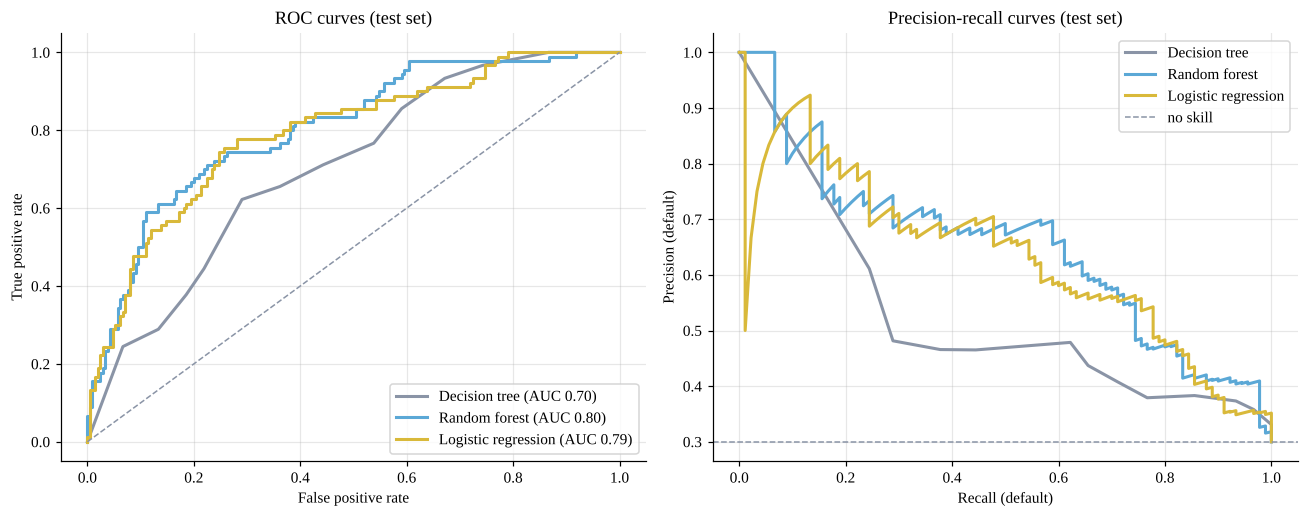

In [18]:
final = fitted[rf_name]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
from sklearn.metrics import roc_curve, precision_recall_curve
for name, color in [('Decision tree (baseline)', GRAY), ('Random forest (challenger)', SKY_EDGE),
                    ('Logistic regression (benchmark)', YELLOW_EDGE)]:
    fpr, tpr, _ = roc_curve(y_arr, probs[name])
    axes[0].plot(fpr, tpr, color=color, linewidth=2, label=f'{name.split(" (")[0]} (AUC {roc_auc_score(y_arr, probs[name]):.2f})')
    p, r, _ = precision_recall_curve(y_arr, probs[name])
    axes[1].plot(r, p, color=color, linewidth=2, label=name.split(' (')[0])
axes[0].plot([0, 1], [0, 1], color=GRAY, linestyle='--', linewidth=1)
axes[0].set_xlabel('False positive rate')
axes[0].set_ylabel('True positive rate')
axes[0].set_title('ROC curves (test set)')
axes[0].legend(loc='lower right')
axes[1].axhline(y_arr.mean(), color=GRAY, linestyle='--', linewidth=1, label='no skill')
axes[1].set_xlabel('Recall (default)')
axes[1].set_ylabel('Precision (default)')
axes[1].set_title('Precision-recall curves (test set)')
axes[1].legend()
plt.tight_layout()
plt.show()

### **3.3 · Cut-off, error costs and confusion matrix**

In [19]:
COST_FN, COST_FP = 5, 1


def total_cost(y, p, cut):
    pred = p >= cut
    return COST_FN * int(((~pred) & (y == 1)).sum()) + COST_FP * int((pred & (y == 0)).sum())


oof = cross_val_predict(clone(final), X_train, y_train, cv=cv, method='predict_proba')[:, 1]
grid = np.linspace(0.05, 0.9, 86)
oof_cost = np.array([total_cost(y_train.values, oof, c) for c in grid])
CUT = grid[int(np.argmin(oof_cost))]
print(f'Cost-optimal cut-off on out-of-fold predictions: {CUT:.2f}  (theoretical 1/6 = {1 / 6:.2f})')

Cost-optimal cut-off on out-of-fold predictions: 0.22  (theoretical 1/6 = 0.17)


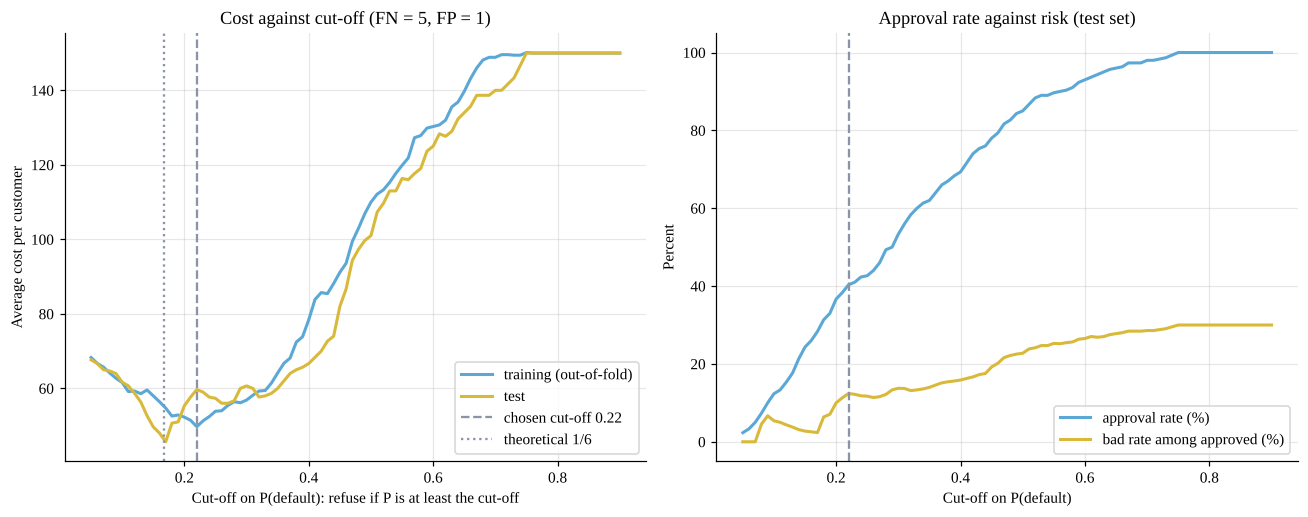

In [20]:
p_test = probs[rf_name]
test_cost = np.array([total_cost(y_arr, p_test, c) for c in grid])
approve = np.array([(p_test < c).mean() for c in grid])
bad_among_approved = np.array([y_arr[p_test < c].mean() if (p_test < c).any() else np.nan for c in grid])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
axes[0].plot(grid, oof_cost / len(y_train) * 100, color=SKY_EDGE, linewidth=2, label='training (out-of-fold)')
axes[0].plot(grid, test_cost / len(y_arr) * 100, color=YELLOW_EDGE, linewidth=2, label='test')
axes[0].axvline(CUT, color=GRAY, linestyle='--', label=f'chosen cut-off {CUT:.2f}')
axes[0].axvline(1 / 6, color=GRAY, linestyle=':', label='theoretical 1/6')
axes[0].set_xlabel('Cut-off on P(default): refuse if P is at least the cut-off')
axes[0].set_ylabel('Average cost per customer')
axes[0].set_title('Cost against cut-off (FN = 5, FP = 1)')
axes[0].legend()
axes[1].plot(grid, approve * 100, color=SKY_EDGE, linewidth=2, label='approval rate (%)')
axes[1].plot(grid, bad_among_approved * 100, color=YELLOW_EDGE, linewidth=2, label='bad rate among approved (%)')
axes[1].axvline(CUT, color=GRAY, linestyle='--')
axes[1].set_xlabel('Cut-off on P(default)')
axes[1].set_ylabel('Percent')
axes[1].set_title('Approval rate against risk (test set)')
axes[1].legend()
plt.tight_layout()
plt.show()

In [21]:
def policy_row(name, cut):
    pred = p_test >= cut
    fp, fn = int((pred & (y_arr == 0)).sum()), int(((~pred) & (y_arr == 1)).sum())
    approved = ~pred
    return {'policy': name, 'refused': int(pred.sum()), 'approval rate': approved.mean(),
            'bad rate among approved': y_arr[approved].mean() if approved.any() else np.nan,
            'false negatives (bad approved)': fn, 'false positives (good refused)': fp,
            'total cost': COST_FN * fn + COST_FP * fp}


policies = pd.DataFrame([policy_row('approve everybody', 2.0), policy_row('cut-off 0.50', 0.5),
                         policy_row(f'chosen cut-off {CUT:.2f}', CUT), policy_row('refuse everybody', 0.0)]).set_index('policy')
policies.round(3)

,refused,approval rate,bad rate among approved,false negatives (bad approved),false positives (good refused),total cost
policy,,,,,,
approve everybody,0,1.000,0.300,90,0,450
cut-off 0.50,45,0.850,0.227,58,13,303
chosen cut-off 0.22,179,0.403,0.124,15,104,179
refuse everybody,300,0.000,NaN,0,210,210


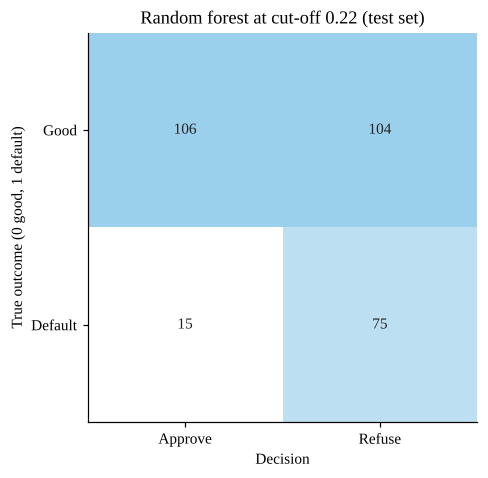

Defaulters caught: 75 of 90 (recall 83%) | good customers refused: 104 of 210 (50%)


In [22]:
pred_cut = p_test >= CUT
cm = confusion_matrix(y_arr, pred_cut)
fig, ax = plt.subplots(figsize=(5.2, 4.6))
ConfusionMatrixDisplay(cm, display_labels=['Approve', 'Refuse']).plot(ax=ax, cmap=SEQ, colorbar=False, values_format='d')
ax.grid(False)
for t in ax.texts:
    t.set_color('#222222')
ax.set_title(f'Random forest at cut-off {CUT:.2f} (test set)')
ax.set_xlabel('Decision')
ax.set_ylabel('True outcome (0 good, 1 default)')
ax.set_yticks([0, 1], ['Good', 'Default'])
plt.show()
tn, fp, fn, tp = cm.ravel()
print(f'Defaulters caught: {tp} of {tp + fn} (recall {tp / (tp + fn):.0%}) | good customers refused: {fp} of {tn + fp} ({fp / (tn + fp):.0%})')

### **3.4 · Calibration and stability**

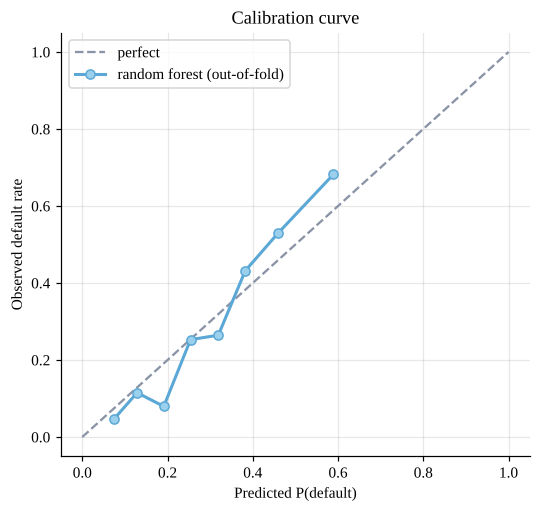

Brier score on the test set: 0.161 (no-skill 0.210)
PSI of the score, training (out-of-fold) vs test: 0.045  (below 0.10 means stable)


In [23]:
frac, mean_pred = calibration_curve(y_train, oof, n_bins=8, strategy='quantile')
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 1], [0, 1], color=GRAY, linestyle='--', label='perfect')
ax.plot(mean_pred, frac, marker='o', color=SKY_EDGE, markerfacecolor=SKY, linewidth=2, label='random forest (out-of-fold)')
ax.set_xlabel('Predicted P(default)')
ax.set_ylabel('Observed default rate')
ax.set_title('Calibration curve')
ax.legend()
plt.show()


def psi(expected, actual, bins=10):
    edges = np.quantile(expected, np.linspace(0, 1, bins + 1))
    edges[0], edges[-1] = -np.inf, np.inf
    e = np.histogram(expected, edges)[0] / len(expected) + 1e-6
    a = np.histogram(actual, edges)[0] / len(actual) + 1e-6
    return float(((a - e) * np.log(a / e)).sum())


print(f'Brier score on the test set: {brier_score_loss(y_arr, p_test):.3f} (no-skill {y_arr.mean() * (1 - y_arr.mean()):.3f})')
print(f'PSI of the score, training (out-of-fold) vs test: {psi(oof, p_test):.3f}  (below 0.10 means stable)')

## **4 · Explainability (XAI)**

### **4.1 · SHAP global explanation**

In [24]:
pre = final.named_steps['pre']
rf_model = final.named_steps['model']
Xt_train, Xt_test = pre.transform(X_train), pre.transform(X_test)
explainer = shap.TreeExplainer(rf_model)
sv = explainer(Xt_test)
sv_bad = sv[:, :, 1]
print('SHAP values:', sv_bad.values.shape, '| base value (mean P(default)):', round(float(sv_bad.base_values[0]), 3))
gap = np.abs(sv_bad.values.sum(1) + sv_bad.base_values - p_test).max()
print('Largest gap between base + sum(SHAP) and the model output:', f'{gap:.1e}')

SHAP values: (300, 57) | base value (mean P(default)): 0.301
Largest gap between base + sum(SHAP) and the model output: 1.4e-15


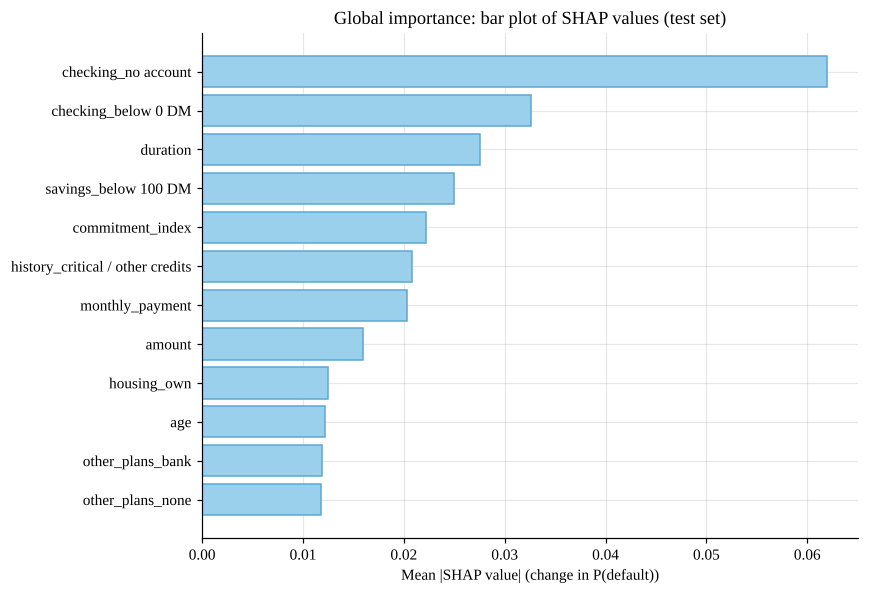

In [25]:
mean_abs = pd.Series(np.abs(sv_bad.values).mean(0), index=Xt_test.columns).sort_values().tail(12)
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(mean_abs.index, mean_abs.values, color=SKY, edgecolor=SKY_EDGE)
ax.set_xlabel('Mean |SHAP value| (change in P(default))')
ax.set_title('Global importance: bar plot of SHAP values (test set)')
plt.tight_layout()
plt.show()

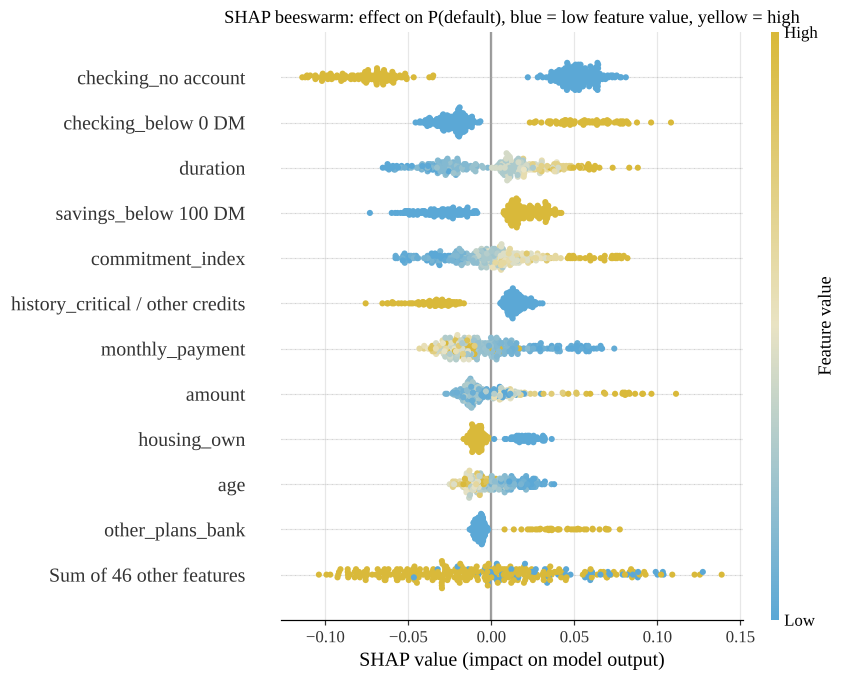

In [26]:
plt.figure(figsize=(9, 6.5))
pastel = LinearSegmentedColormap.from_list('feat', [SKY_EDGE, '#E9E3C4', YELLOW_EDGE])
shap.plots.beeswarm(sv_bad, max_display=12, color=pastel, show=False)
plt.title('SHAP beeswarm: effect on P(default), blue = low feature value, yellow = high')
plt.tight_layout()
plt.show()

In [27]:
perm = permutation_importance(final, X_test, y_test, scoring='roc_auc', n_repeats=30, random_state=SEED)
pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False).head(6).round(3).rename('AUC drop').to_frame()

,AUC drop
checking,0.107
monthly_payment,0.019
history,0.016
savings,0.014
amount,0.013
purpose,0.009


### **4.2 · Local explanation for two customers**

In [28]:
p_series = pd.Series(p_test, index=test.index)
low_risk = int(p_series[test['default'] == 0].idxmin())
high_risk = int(p_series[test['default'] == 1].idxmax())
for name, i in [('Low-risk, approved', low_risk), ('High-risk, refused', high_risk)]:
    print(f'{name}: test row {i}, P(default) = {p_series[i]:.2f}, actual default = {int(test.loc[i, "default"])}')

Low-risk, approved: test row 12, P(default) = 0.02, actual default = 0
High-risk, refused: test row 54, P(default) = 0.75, actual default = 1


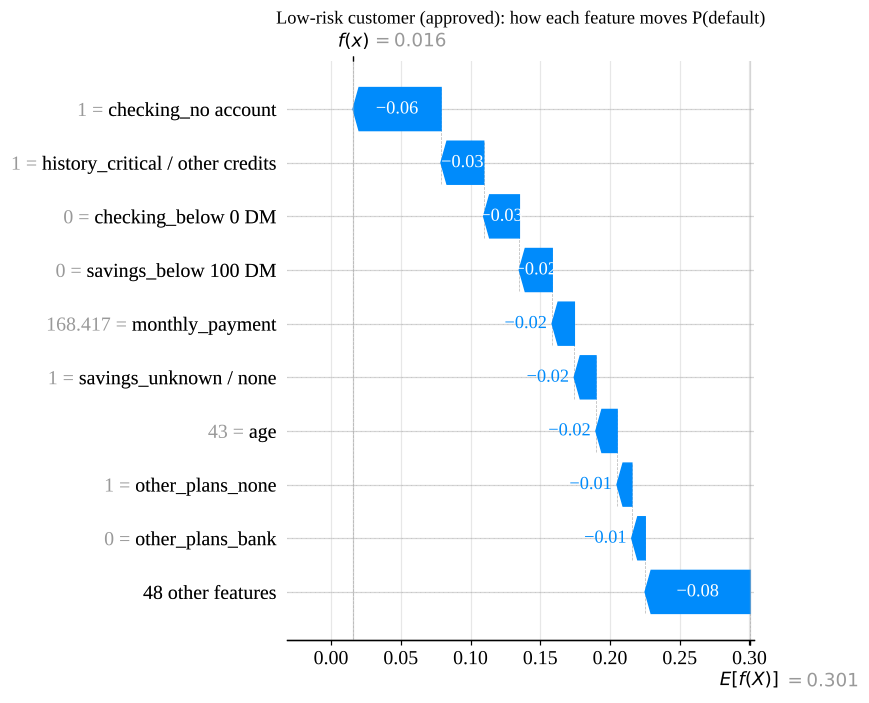

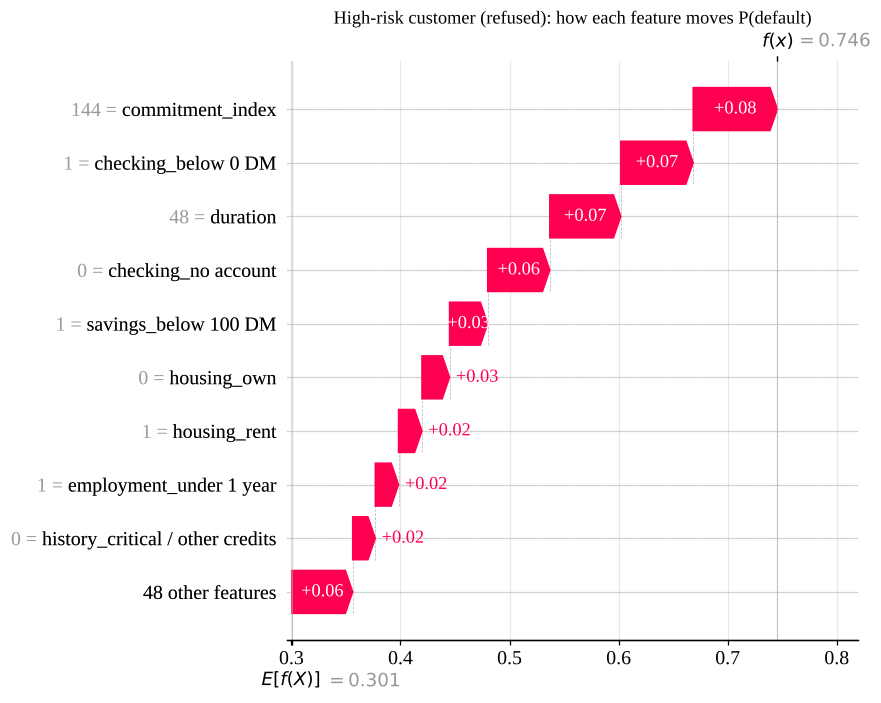

In [29]:
for name, i in [('Low-risk customer (approved)', low_risk), ('High-risk customer (refused)', high_risk)]:
    shap.plots.waterfall(sv_bad[i], max_display=10, show=False)
    plt.title(f'{name}: how each feature moves P(default)')
    plt.tight_layout()
    plt.show()

In [30]:
def readable(i):
    row = pd.DataFrame({'value': Xt_test.iloc[i], 'SHAP': sv_bad.values[i]})
    row = row[row['value'] != 0]
    return row.reindex(row['SHAP'].abs().sort_values(ascending=False).index).head(6).round(3)


print('Refused customer: strongest factors (value 1 = the category applies)')
display(readable(high_risk))
print('Approved customer:')
display(readable(low_risk))

Refused customer: strongest factors (value 1 = the category applies)


,value,SHAP
commitment_index,144.0,0.077
checking_below 0 DM,1.0,0.066
duration,48.0,0.065
savings_below 100 DM,1.0,0.035
housing_rent,1.0,0.021
employment_under 1 year,1.0,0.021


Approved customer:


,value,SHAP
checking_no account,1.000,-0.063
history_critical / other credits,1.000,-0.031
monthly_payment,168.417,-0.016
savings_unknown / none,1.000,-0.016
age,43.000,-0.015
other_plans_none,1.000,-0.011


### **4.3 · LIME (optional): comparison for the refused customer**

In [31]:
from lime.lime_tabular import LimeTabularExplainer

lime_explainer = LimeTabularExplainer(Xt_train.values, feature_names=list(Xt_train.columns),
                                      class_names=['good', 'default'], mode='classification', random_state=SEED)
lime_exp = lime_explainer.explain_instance(Xt_test.values[high_risk], rf_model.predict_proba, num_features=8, num_samples=5000)
lime_top = pd.DataFrame(lime_exp.as_list(), columns=['LIME rule', 'weight'])
shap_top = readable(high_risk).reset_index().rename(columns={'index': 'SHAP feature'})[['SHAP feature', 'SHAP']]
display(lime_top.round(3))
shap_names = set(readable(high_risk).head(5).index)
lime_names = [r for r in lime_top['LIME rule'].head(5)]
print('SHAP top 5:', sorted(shap_names))
print('LIME top 5:', lime_names)

,LIME rule,weight
0,checking_no account <= 0.00,0.118
1,0.00 < checking_below 0 DM <= 1.00,0.070
2,commitment_index > 96.00,0.062
3,duration > 24.00,0.051
4,purpose_education <= 0.00,-0.050
5,0.00 < savings_below 100 DM <= 1.00,0.049
6,other_plans_bank <= 0.00,-0.047
7,history_critical / other credits <= 0.00,0.045


SHAP top 5: ['checking_below 0 DM', 'commitment_index', 'duration', 'housing_rent', 'savings_below 100 DM']
LIME top 5: ['checking_no account <= 0.00', '0.00 < checking_below 0 DM <= 1.00', 'commitment_index > 96.00', 'duration > 24.00', 'purpose_education <= 0.00']


### **4.4 · Segment audit (fairness)**

In [32]:
audit = test.copy()
audit['refused'] = p_test >= CUT
audit['age group'] = pd.cut(audit['age'], [0, 25, 40, 120], labels=['under 25', '25 to 40', 'over 40'])
rows = []
for col in ['age group', 'foreign', 'personal_status']:
    for level, g in audit.groupby(col, observed=True):
        approved = g[~g['refused']]
        rows.append({'segment': f'{col}: {level}', 'customers': len(g), 'actual default rate': g['default'].mean(),
                     'refusal rate': g['refused'].mean(),
                     'bad rate among approved': approved['default'].mean() if len(approved) else np.nan,
                     'recall': (g['refused'] & (g['default'] == 1)).sum() / max((g['default'] == 1).sum(), 1)})
pd.DataFrame(rows).set_index('segment').round(2)

,customers,actual default rate,refusal rate,bad rate among approved,recall
segment,,,,,
age group: under 25,66,0.45,0.71,0.32,0.80
age group: 25 to 40,147,0.27,0.59,0.07,0.90
age group: over 40,87,0.24,0.52,0.12,0.76
foreign: no,9,0.22,0.22,0.00,1.00
foreign: yes,291,0.30,0.61,0.13,0.83
personal_status: female div./married,101,0.35,0.61,0.18,0.80
personal_status: male divorced,12,0.50,0.92,0.00,1.00
personal_status: male married,25,0.24,0.60,0.20,0.67
personal_status: male single,162,0.27,0.56,0.08,0.86


## **5 · LLM explanation for a refused customer (bonus)**

In [33]:
FACTS = {
    'checking_below 0 DM': 'The current account is overdrawn (below zero).',
    'checking_0-200 DM': 'The current account balance is low.',
    'checking_no account': 'The customer has no current account with us.',
    'duration': 'The requested loan runs for a long time.',
    'amount': 'The requested amount is high.',
    'monthly_payment': 'The monthly instalment is high.',
    'commitment_index': 'The loan is long and the instalments take a large share of income.',
}


def describe(feature, value):
    if feature in FACTS:
        return FACTS[feature]
    if feature.startswith('savings_'):
        return f'Savings level: {feature.split("_", 1)[1]}.'
    if feature.startswith('history_'):
        return f'Credit history: {feature.split("_", 1)[1]}.'
    if feature.startswith('employment_'):
        return f'Time in current job: {feature.split("_", 1)[1]}.'
    if feature.startswith('purpose_'):
        return f'Purpose of the loan: {feature.split("_", 1)[1]}.'
    return f'{feature} = {value:g}.'


contrib = readable(high_risk)
risk_up = contrib[contrib['SHAP'] > 0].head(4)
facts = [f'- {describe(f, v)}' for f, v in zip(risk_up.index, risk_up['value'])]
prompt = f"""You are a polite customer-service writer at a bank.
A loan application was declined. Write a short letter to the customer.
Rules:
1. Plain, respectful language. No technical words (no model, score, SHAP, probability).
2. Explain in 3 sentences at most which facts counted against the application.
3. Give 3 concrete steps the customer can take in the coming months to improve their chances.
4. Do not promise approval. Do not mention age, sex, nationality or family status.

Facts that counted against the application (strongest first):
{chr(10).join(facts)}
"""
print(prompt)

You are a polite customer-service writer at a bank.
A loan application was declined. Write a short letter to the customer.
Rules:
1. Plain, respectful language. No technical words (no model, score, SHAP, probability).
2. Explain in 3 sentences at most which facts counted against the application.
3. Give 3 concrete steps the customer can take in the coming months to improve their chances.
4. Do not promise approval. Do not mention age, sex, nationality or family status.

Facts that counted against the application (strongest first):
- The loan is long and the instalments take a large share of income.
- The current account is overdrawn (below zero).
- The requested loan runs for a long time.
- Savings level: below 100 DM.



**Sample LLM output** (generated by ChatGPT from the prompt above)

Dear Customer,

Thank you for your loan application. After carefully reviewing your application, we regret to inform you that we are unable to approve it at this time.

The main reasons are that the monthly instalments would take up a large part of your income, your current account is overdrawn, and the requested repayment period is quite long. In addition, your current savings are below 100 DM.

To improve your chances of a successful application in the coming months, we recommend that you:

1. Bring your current account back above zero: Avoid further overdrafts.
2. Build up your savings: Try to save a small amount regularly to create a financial reserve.
3. Review your loan request: Consider borrowing a smaller amount or choosing a shorter repayment period with affordable monthly instalments.

You are welcome to apply again once your financial situation has improved, but approval cannot be guaranteed.

Kind regards,
Customer Service Team

**1. Cause and effect.** SHAP explains the model, not the world: a large SHAP value means a variable moves the prediction, not that changing it changes the customer's risk.

- **Likely direct causes:** loan terms (`duration`, `amount`, `installment_rate`, `monthly_payment`, `commitment_index`). A heavier repayment burden makes missed payments more likely.
- **Signals only:** `checking`, `savings`, `employment`, `property`. They reflect financial slack; income and job stability are the hidden confounders behind them.
- **Not causes:** `age`, `housing`, `job`, `telephone` (demographic markers). Education, the brief's example, is not in this dataset.
- **Selection effect:** customers with a critical credit history default less than clean ones. Bad history cannot protect; the bank approved them only when other signals were strong, and the model learns this reversed pattern.

**2. Decisions.** Set policy on what the bank controls: amount, duration, instalment, limits and pricing, and test it with a randomised pilot or A/B test. Balance, age, job and housing are not levers: forcing the number does not change the situation behind it, and some are protected attributes. Relying on correlation alone is risky because (a) patterns break when policy changes, (b) the sample has approved customers only (reject inference), (c) proxies can cause unfair treatment and legal risk, (d) "raise your balance" advice costs the customer money and may not lower risk.

1. **Target coding.** `german.doc` uses 1 = good, 2 = bad. The brief wants 0 = good, 1 = bad. Using the raw code flips precision, recall and AUC.
2. **"Check missing values".** There are none. `A65` (savings unknown) and `A124` (no property) are real categories.
3. **Suggested features cannot be built.** The brief asks for debt-to-income and limit utilisation. The data has no income, limit or balance. Only a 4-level `installment_rate` band exists.
4. **The causality example uses education.** That column does not exist here (it belongs to *Give Me Some Credit*).
5. **Class imbalance is mild.** 30% defaults (2.3 : 1), not rare. The PR-AUC of a random model is 0.30, not close to 0.
6. **Out-of-time validation is impossible.** The slides recommend it, but there is no date column. A stratified random split of 1000 rows gives a test set of only 300 (90 defaults), so model differences are mostly noise (confidence intervals are shown).
7. **The cost matrix is missing from the brief.** `german.doc` gives 5 : 1 and it drives the cut-off.
8. **Protected attributes.** Sex (inside `personal_status`), age and foreign-worker status are in the data. They are excluded or audited.
9. **Old and selected sample.** The data is from 1994 (Deutsche Mark) and contains approved loans only, so it cannot be used as a production model.